# Patient Readmission Prediction: Machine Learning Case Study

**Objective:** Predict whether an admission will be followed by a readmission within 30 days of discharge.

This notebook follows the five tasks in the BrightLearn assessment rubric:
1. Data preprocessing
2. Exploratory data analysis
3. Feature selection
4. Model building
5. Model evaluation and testing




##Task 1 — Data preprocessing

### 1.1 Load the data




In [0]:
# Import the libraries used throughout the notebook.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the source table from Databricks into a Spark DataFrame.
spark_df = spark.read.table("patient.readmission.patient_readmission_data")

# Convert the Spark DataFrame to Pandas once for this analysis.
# Keep the Pandas DataFrame in the variable df for consistency.
df = spark_df.toPandas()

# Display a small preview and confirm the dataset dimensions.
display(df.head())
print("Dataset shape (rows, columns):", df.shape)


Patient ID,Age,Gender,Admission Type,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Readmission
1,62,Female,Elective,4,5,110,130,1,No
2,65,Male,Emergency,19,2,157,81,4,No
3,82,Female,Emergency,18,4,74,84,0,No
4,85,Male,Emergency,2,4,106,85,4,No
5,85,Female,Elective,19,3,80,119,3,No


Dataset shape (rows, columns): (3000, 10)


### 1.2 Audit the data before making changes




In [0]:
# Display the column names and data types.
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)




Column names:
['Patient ID', 'Age', 'Gender', 'Admission Type', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions', 'Readmission']

Data types:
Patient ID              int64
Age                     int64
Gender                 object
Admission Type         object
Length of Stay          int64
Number of Diagnoses     int64
Blood Pressure          int64
Blood Sugar Levels      int64
Previous Admissions     int64
Readmission            object
dtype: object


In [0]:
# Check missing values and their percentages for every column.
missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})
display(missing_summary)



Missing values,Missing percentage
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0


In [0]:
# Check exact duplicate rows without deleting anything.
print("Exact duplicate rows:", df.duplicated().sum())



Exact duplicate rows: 0


In [0]:
# Check whether Patient ID is repeated.
# The case-study brief describes each row as an admission record.
print("Duplicate Patient IDs:", df["Patient ID"].duplicated().sum())



Duplicate Patient IDs: 0


In [0]:
# Review numeric descriptive statistics.
display(df.describe(include="all").T)



count,unique,top,freq,mean,std,min,25%,50%,75%,max
3000.0,null,null,null,1500.5,866.1697293256098,1.0,750.75,1500.5,2250.25,3000.0
3000.0,null,null,null,53.453,20.89299635680791,18.0,35.0,53.0,72.0,89.0
3000.0,2,Male,1555,null,null,null,null,null,null,null
3000.0,2,Elective,1563,null,null,null,null,null,null,null
3000.0,null,null,null,15.226333333333333,8.264857884289647,1.0,8.0,15.0,22.0,29.0
3000.0,null,null,null,4.956666666666667,2.5750726634335734,1.0,3.0,5.0,7.0,9.0
3000.0,null,null,null,119.058,34.08926510401445,60.0,89.75,119.0,147.25,179.0
3000.0,null,null,null,133.536,37.62631105704164,51.0,101.0,133.0,167.0,199.0
3000.0,null,null,null,1.9583333333333333,1.4016366923569539,0.0,1.0,2.0,3.0,4.0
3000.0,2,No,2134,null,null,null,null,null,null,null


In [0]:
# Review the categories in text columns, including missing values.
categorical_audit_columns = df.select_dtypes(include=["object", "string", "category"]).columns
for column in categorical_audit_columns:
    print(f"\nValues in {column}:")
    print(df[column].value_counts(dropna=False))


Values in Gender:
Gender
Male      1555
Female    1445
Name: count, dtype: int64

Values in Admission Type:
Admission Type
Elective     1563
Emergency    1437
Name: count, dtype: int64

Values in Readmission:
Readmission
No     2134
Yes     866
Name: count, dtype: int64


### 1.3 Prepare a modelling copy and document the cleaning rules



In [0]:
# Create a separate modelling copy so the original df remains unchanged.
model_df = df.copy()

# Remove accidental leading or trailing spaces from column names.
model_df.columns = model_df.columns.str.strip()




In [0]:
# Confirm that the expected fields are present.
expected_columns = [
    "Patient ID", "Age", "Gender", "Admission Type", "Length of Stay",
    "Number of Diagnoses", "Blood Pressure", "Blood Sugar Levels",
    "Previous Admissions", "Readmission"
]
missing_columns = [column for column in expected_columns if column not in model_df.columns]
print("Expected columns not found:", missing_columns)
assert not missing_columns, "Check the source table: one or more expected columns are missing."



Expected columns not found: []


In [0]:
# Trim leading/trailing spaces from text columns without changing df.
text_columns = model_df.select_dtypes(include=["object", "string", "category"]).columns
for column in text_columns:
    model_df[column] = model_df[column].astype("string").str.strip()



In [0]:
# Standardise the target labels to No and Yes.
model_df["Readmission"] = model_df["Readmission"].str.title()



In [0]:
# Check the target labels and confirm that df was not changed.
print("Target categories after standardisation:", model_df["Readmission"].unique())
print("Original df shape:", df.shape)
print("Modelling copy shape:", model_df.shape)

Target categories after standardisation: <StringArray>
['No', 'Yes']
Length: 2, dtype: string
Original df shape: (3000, 10)
Modelling copy shape: (3000, 10)


### 1.4 Define the prediction point, predictors and target; split the data



In [0]:
# Define the candidate predictor columns.
feature_columns = [
    "Age",
    "Gender",
    "Admission Type",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]



In [0]:
# Create X (predictors) and y (outcome) from the modelling copy.
X = model_df[feature_columns].copy()
y = model_df["Readmission"].copy()

# Check that the target contains the expected two classes.
print("Target counts:")
print(y.value_counts(dropna=False))



Target counts:
Readmission
No     2134
Yes     866
Name: count, dtype: Int64


In [0]:
# Split into 80% training data and 20% test data.
# Stratification preserves a similar Yes/No ratio in both sets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)




In [0]:
# Display the split sizes and target percentages.
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

split_balance = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training set (%)": y_train.value_counts(normalize=True) * 100,
    "Test set (%)": y_test.value_counts(normalize=True) * 100
}).fillna(0)
display(split_balance.round(2))


Training set: (2400, 8)
Test set: (600, 8)


Full dataset (%),Training set (%),Test set (%)
71.13,71.12,71.17
28.87,28.88,28.83


### 1.5 Build preprocessing pipelines



In [0]:
# Import preprocessing and pipeline tools.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numeric and categorical columns from the training predictors.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)



Numeric features: ['Age', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions']
Categorical features: ['Gender', 'Admission Type']


In [0]:
# Numeric pipeline: fill missing values, then standardise the values.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])



In [0]:
# Categorical pipeline: fill missing values, then one-hot encode categories.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])



In [0]:
# Apply each preprocessing pipeline to its matching columns.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


## Task 2 — Exploratory data analysis 




In [0]:
# 2.1 Show the number and percentage of No and Yes outcomes.
target_counts = model_df["Readmission"].value_counts()
target_percentages = model_df["Readmission"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Admissions": target_counts,
    "Percentage": target_percentages.round(2)
})
display(target_summary)



Admissions,Percentage
2134,71.13
866,28.87


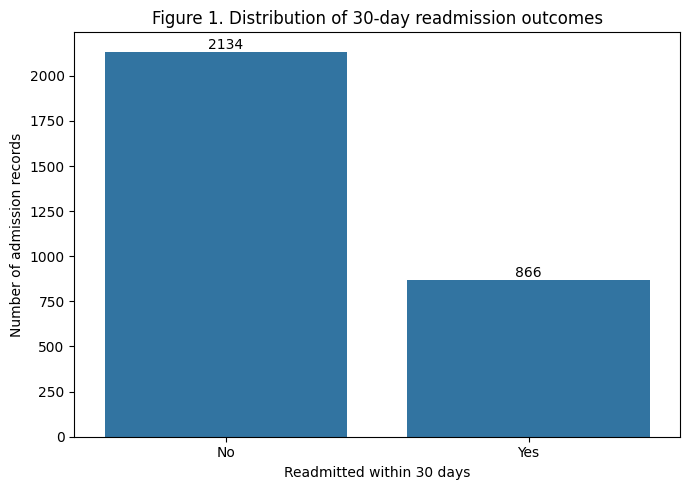

In [0]:
# Plot the target distribution.
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=model_df, x="Readmission", order=["No", "Yes"])
for container in ax.containers:
    ax.bar_label(container)
plt.title("Figure 1. Distribution of 30-day readmission outcomes")
plt.xlabel("Readmitted within 30 days")
plt.ylabel("Number of admission records")
plt.tight_layout()
plt.show()

# Interpretation: state the percentage of Yes cases and explain why
# accuracy alone may be misleading when the classes are imbalanced.


In [0]:
# 2.2 Summarise and plot the distributions of all numeric predictors.
numeric_for_eda = [
    "Age", "Length of Stay", "Number of Diagnoses",
    "Blood Pressure", "Blood Sugar Levels", "Previous Admissions"
]

display(model_df[numeric_for_eda].describe().T)



count,mean,std,min,25%,50%,75%,max
3000.0,53.453,20.89299635680791,18.0,35.0,53.0,72.0,89.0
3000.0,15.226333333333333,8.264857884289647,1.0,8.0,15.0,22.0,29.0
3000.0,4.956666666666667,2.5750726634335734,1.0,3.0,5.0,7.0,9.0
3000.0,119.058,34.08926510401445,60.0,89.75,119.0,147.25,179.0
3000.0,133.536,37.62631105704164,51.0,101.0,133.0,167.0,199.0
3000.0,1.9583333333333333,1.4016366923569539,0.0,1.0,2.0,3.0,4.0


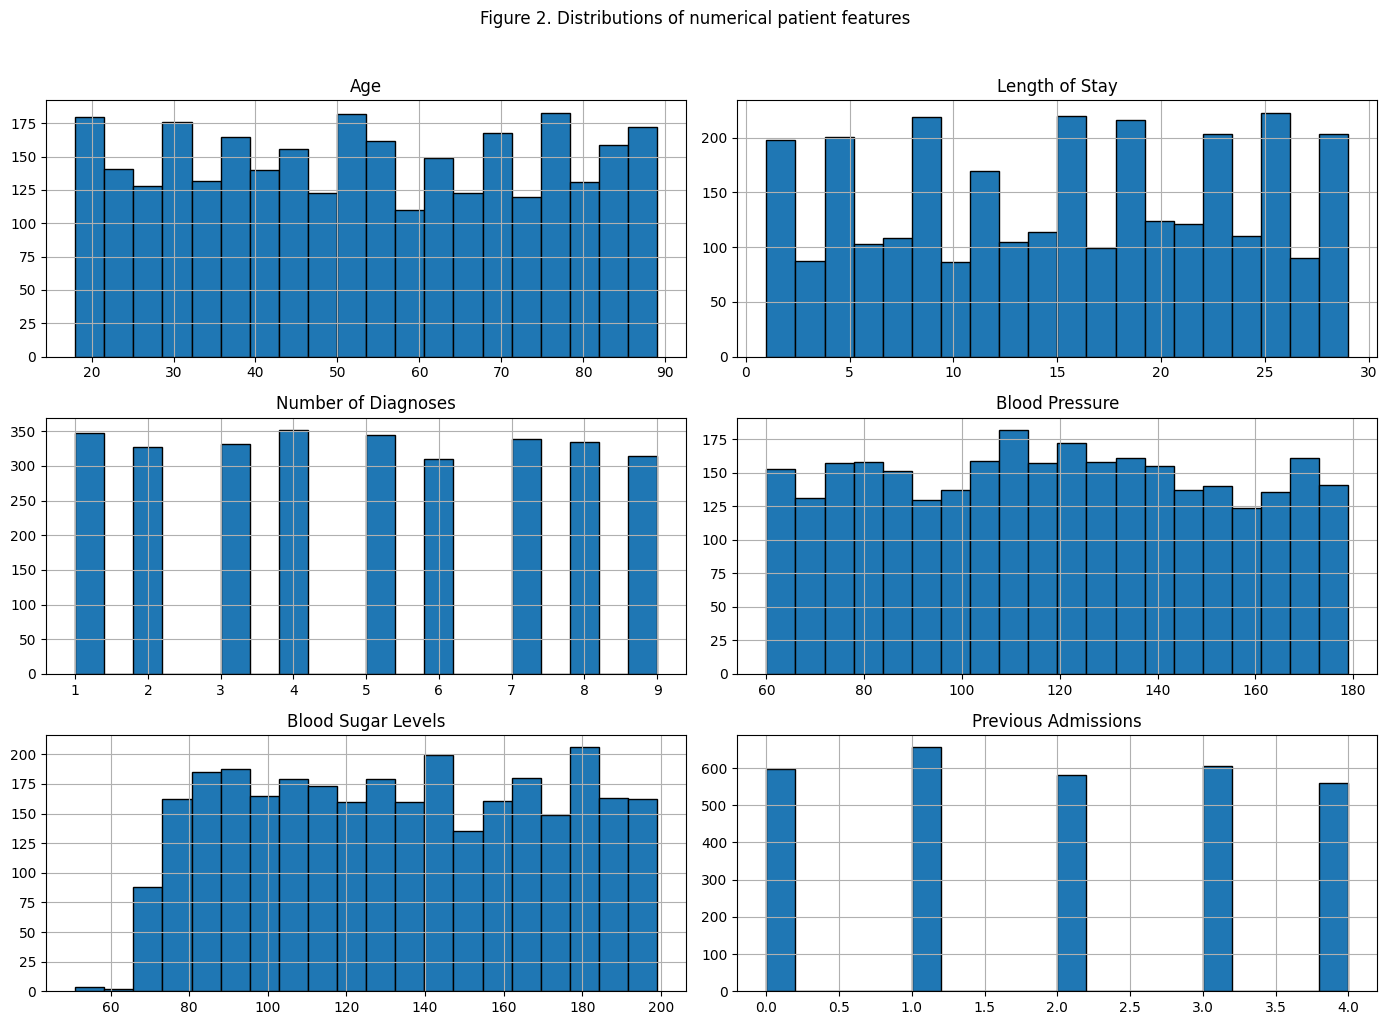

In [0]:
# Draw a histogram for each numeric predictor.
model_df[numeric_for_eda].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Figure 2. Distributions of numerical patient features", y=1.02)
plt.tight_layout()
plt.show()

# Interpretation: comment on shape, spread, skew and possible unusual values.


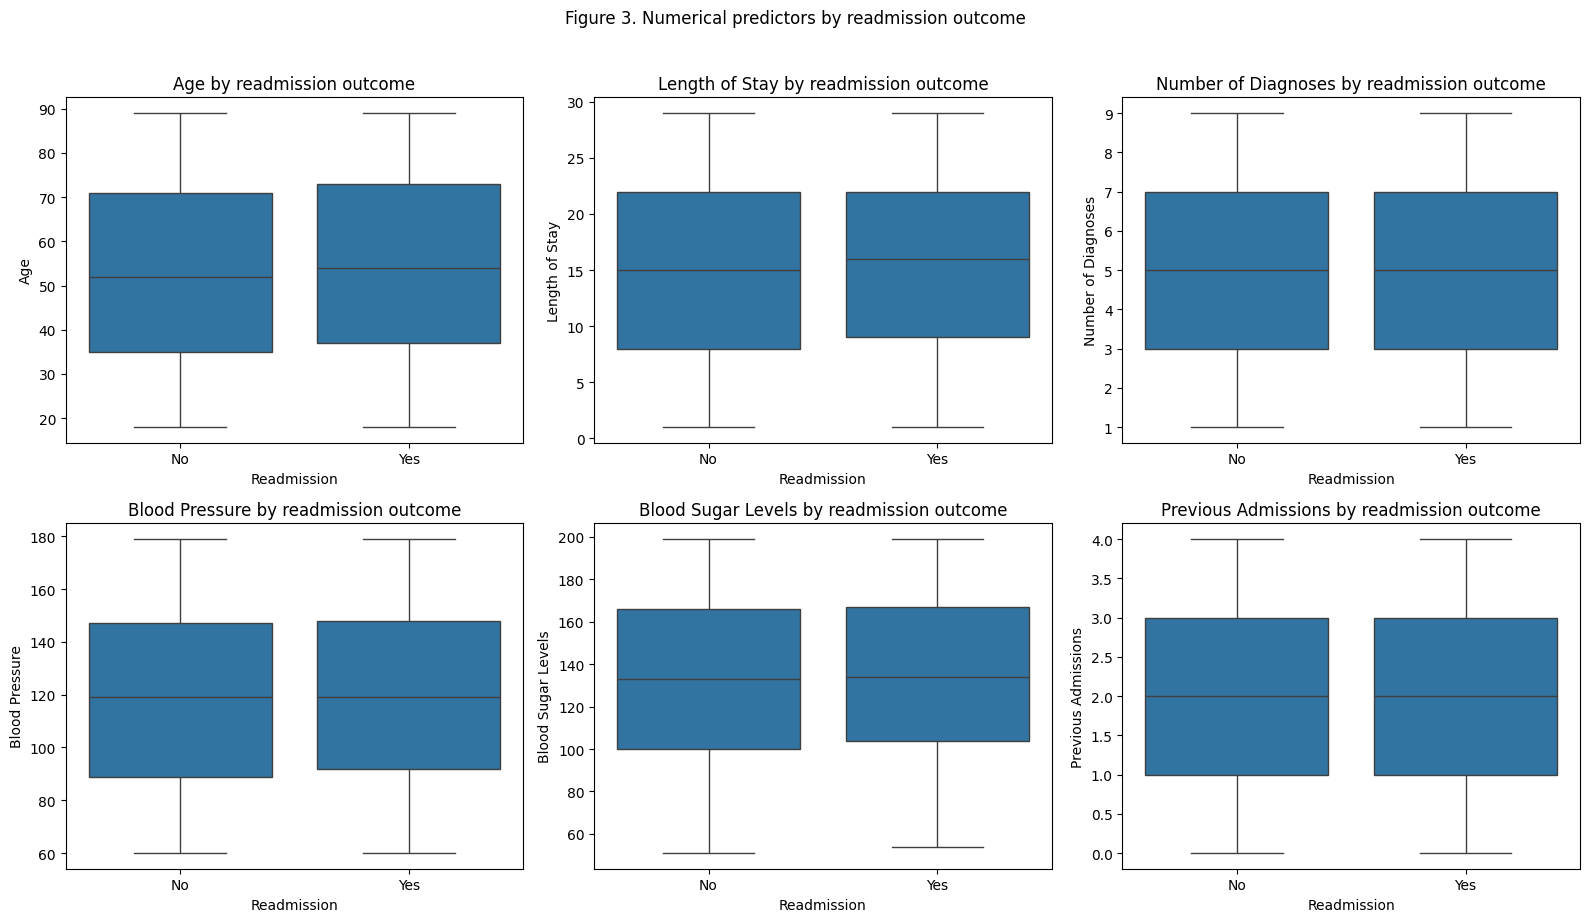

In [0]:
# 2.3 Compare numerical feature distributions for No and Yes outcomes.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_for_eda):
    # Boxplots compare medians, spread and possible outliers by outcome.
    sns.boxplot(
        data=model_df,
        x="Readmission",
        y=feature,
        order=["No", "Yes"],
        ax=ax
    )
    ax.set_title(f"{feature} by readmission outcome")
    ax.set_xlabel("Readmission")
    ax.set_ylabel(feature)

plt.suptitle("Figure 3. Numerical predictors by readmission outcome", y=1.02)
plt.tight_layout()
plt.show()

# Interpretation: describe which variables appear to differ between groups.


In [0]:
# 2.4 Calculate and plot readmission rates by categorical predictors.
categorical_for_eda = ["Gender", "Admission Type"]

# Create a temporary flag for the calculation; model_df is not modified.
readmission_flag = (model_df["Readmission"] == "Yes").astype(int)

for feature in categorical_for_eda:
    rate_data = model_df[[feature]].copy()
    rate_data["Readmitted_Flag"] = readmission_flag

    # The mean of a 0/1 flag is the proportion of Yes outcomes.
    rate_table = (
        rate_data.groupby(feature, dropna=False)["Readmitted_Flag"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Admissions", "mean": "Readmission rate"})
    )
    rate_table["Readmission rate (%)"] = (rate_table["Readmission rate"] * 100).round(2)
    print(f"Readmission rate by {feature}:")
    display(rate_table)

    
    

Readmission rate by Gender:


Admissions,Readmission rate,Readmission rate (%)
1445,0.2816608996539792,28.17
1555,0.29517684887459805,29.52


Readmission rate by Admission Type:


Admissions,Readmission rate,Readmission rate (%)
1563,0.29366602687140114,29.37
1437,0.28322894919972164,28.32


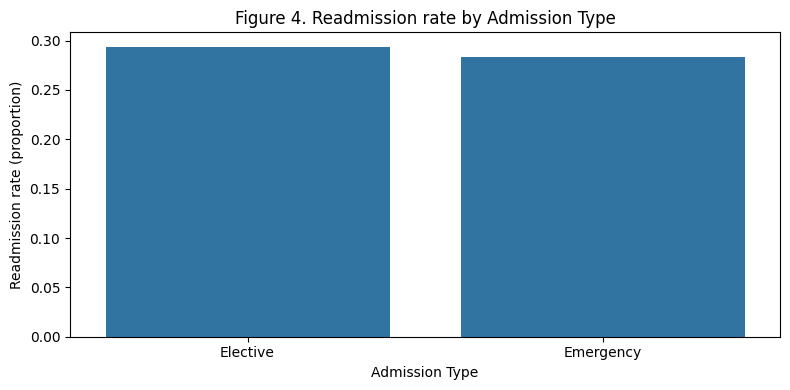

In [0]:
# Plot the readmission rate for each category.
plt.figure(figsize=(8,4))
sns.barplot(data=rate_data, x=feature, y="Readmitted_Flag", errorbar=None)
plt.title(f"Figure 4. Readmission rate by {feature}")
plt.xlabel(feature)
plt.ylabel("Readmission rate (proportion)")
plt.tight_layout()
plt.show()

# Interpretation: compare percentages, not just category counts.


In [0]:
# 2.5 Compare the count-based features by readmission outcome.
count_features = ["Number of Diagnoses", "Previous Admissions"]

for feature in count_features:
    summary = model_df.groupby("Readmission")[feature].agg(
        Admissions="count",
        Mean="mean",
        Median="median"
    ).round(2)
    print(f"{feature} by readmission outcome:")
    display(summary)

# Interpretation: state whether the group averages/medians differ noticeably.


Number of Diagnoses by readmission outcome:


Admissions,Mean,Median
2134,4.94,5.0
866,4.99,5.0


Previous Admissions by readmission outcome:


Admissions,Mean,Median
2134,1.96,2.0
866,1.94,2.0


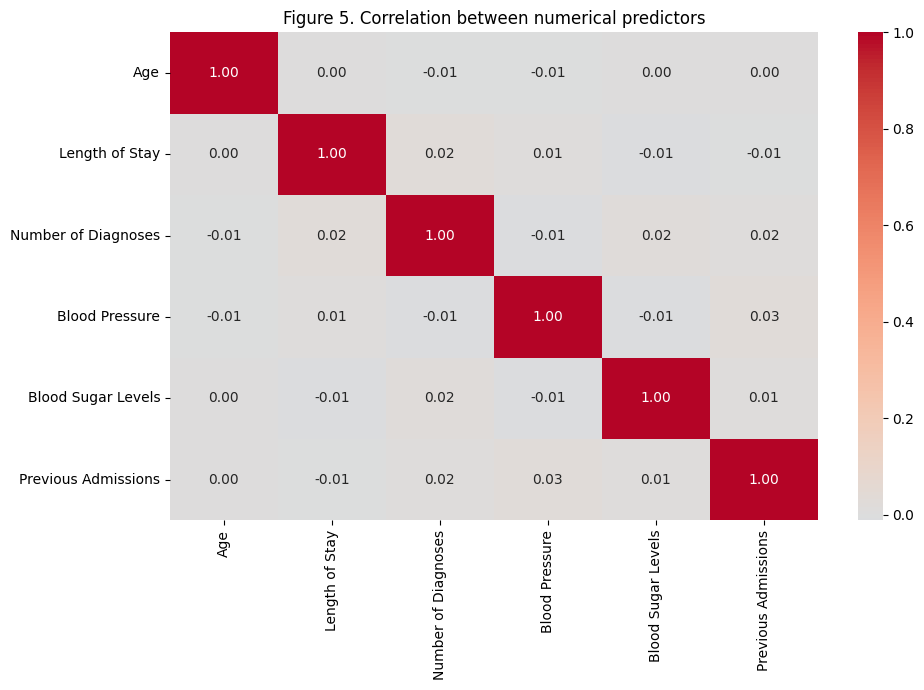

In [0]:
# 2.6 Examine correlations among numerical predictors.
# Patient ID and the target are excluded from this numeric correlation matrix.

correlation_matrix = model_df[numeric_for_eda].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Figure 5. Correlation between numerical predictors")
plt.tight_layout()
plt.show()

# Interpretation: identify strong correlations that may indicate redundancy.
# A small correlation should not be described as a strong relationship.


## Task 3 — Feature selection 

Feature selection is performed using the **training data only**. The held-out test data must not influence which features are selected.

We use:
1. Chi-square tests for categorical predictors.
2. Mann–Whitney U tests for numerical predictors, with an effect-size estimate.
3. Mutual information to detect statistical dependence that may not be linear.
4. Random Forest permutation importance to estimate how much each feature contributes to predictive performance.

A small p-value does not automatically mean a feature is practically important. Use the results together with EDA, redundancy, availability at discharge and ethical considerations.


In [0]:
# 3.1 Import statistical tests and feature-selection tools.
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance



In [0]:
# Make a numeric 0/1 target for statistical tests.
y_train_binary = (y_train == "Yes").astype(int)

# Prepare a list to collect one statistical result per original predictor.
statistical_results = []

# Test categorical predictors with the chi-square test of independence.
for feature in categorical_features:
    contingency_table = pd.crosstab(X_train[feature], y_train)
    chi2_stat, p_value, degrees_freedom, expected = chi2_contingency(contingency_table)

    statistical_results.append({
        "Feature": feature,
        "Test": "Chi-square",
        "Statistic": chi2_stat,
        "P-value": p_value,
        "Effect size": np.nan
    })

# Test numerical predictors with Mann–Whitney U.
# Rank-biserial correlation is included as an effect-size measure.
for feature in numeric_features:
    yes_values = X_train.loc[y_train == "Yes", feature].dropna()
    no_values = X_train.loc[y_train == "No", feature].dropna()

    u_stat, p_value = mannwhitneyu(
        yes_values, no_values, alternative="two-sided"
    )

    # Rank-biserial correlation gives a scale-free effect-size estimate.
    n_yes = len(yes_values)
    n_no = len(no_values)
    rank_biserial = (2 * u_stat) / (n_yes * n_no) - 1

    statistical_results.append({
        "Feature": feature,
        "Test": "Mann–Whitney U",
        "Statistic": u_stat,
        "P-value": p_value,
        "Effect size": rank_biserial
    })

statistical_results_df = pd.DataFrame(statistical_results)
display(statistical_results_df.round(4))


Feature,Test,Statistic,P-value,Effect size
Gender,Chi-square,1.0156,0.3136,null
Admission Type,Chi-square,2.4937,0.1143,null
Age,Mann–Whitney U,610242.5,0.2225,0.0317
Length of Stay,Mann–Whitney U,603443.0,0.4364,0.0202
Number of Diagnoses,Mann–Whitney U,600195.0,0.5685,0.0147
Blood Pressure,Mann–Whitney U,592800.5,0.9314,0.0022
Blood Sugar Levels,Mann–Whitney U,602612.5,0.4691,0.0188
Previous Admissions,Mann–Whitney U,588022.5,0.8188,-0.0058


In [0]:
# 3.2 Calculate mutual information on the training data.
# Fit preprocessing using X_train only, then calculate MI against y_train.
X_train_encoded = preprocessor.fit_transform(X_train)

# Get the transformed feature names after one-hot encoding.
encoded_feature_names = preprocessor.get_feature_names_out()



In [0]:
# Mutual information requires a dense numeric array for this calculation.
if hasattr(X_train_encoded, "toarray"):
    X_train_encoded_dense = X_train_encoded.toarray()
else:
    X_train_encoded_dense = np.asarray(X_train_encoded)

mi_values = mutual_info_classif(
    X_train_encoded_dense,
    y_train_binary,
    random_state=42
)

# Map encoded columns back to their original predictor names.
mi_detail = pd.DataFrame({
    "Encoded feature": encoded_feature_names,
    "Mutual information": mi_values
})

def original_feature_name(encoded_name):
    # Remove the transformer prefix, such as numeric__ or categorical__.
    clean_name = encoded_name.split("__", 1)[-1]
    # Match the original feature name, including names containing spaces.
    for original_name in feature_columns:
        if clean_name == original_name or clean_name.startswith(original_name + "_"):
            return original_name
    return clean_name

mi_detail["Feature"] = mi_detail["Encoded feature"].apply(original_feature_name)

# Sum one-hot category contributions to produce one MI score per original field.
mi_summary = (
    mi_detail.groupby("Feature", as_index=False)["Mutual information"]
    .sum()
    .sort_values("Mutual information", ascending=False)
)

display(mi_summary.round(4))


Feature,Mutual information
Gender,0.01
Age,0.0087
Number of Diagnoses,0.0053
Admission Type,0.0
Blood Pressure,0.0
Blood Sugar Levels,0.0
Length of Stay,0.0
Previous Admissions,0.0


In [0]:
# 3.3 Fit a Random Forest on training data and calculate permutation importance.
# The pipeline keeps preprocessing inside the model.
feature_selection_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit this exploratory feature-importance model using training data only.
feature_selection_model.fit(X_train, y_train)

# Permute one original input feature at a time and measure the ROC-AUC drop.
permutation_result = permutation_importance(
    feature_selection_model,
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_summary = pd.DataFrame({
    "Feature": X_train.columns,
    "Permutation importance mean": permutation_result.importances_mean,
    "Permutation importance std": permutation_result.importances_std
}).sort_values("Permutation importance mean", ascending=False)

display(permutation_summary.round(4))



Feature,Permutation importance mean,Permutation importance std
Blood Sugar Levels,0.0548,0.0035
Length of Stay,0.0315,0.0036
Age,0.024,0.0017
Blood Pressure,0.0189,0.0014
Number of Diagnoses,0.0106,0.0014
Admission Type,0.0043,5.0E-4
Previous Admissions,0.0037,7.0E-4
Gender,0.0032,4.0E-4


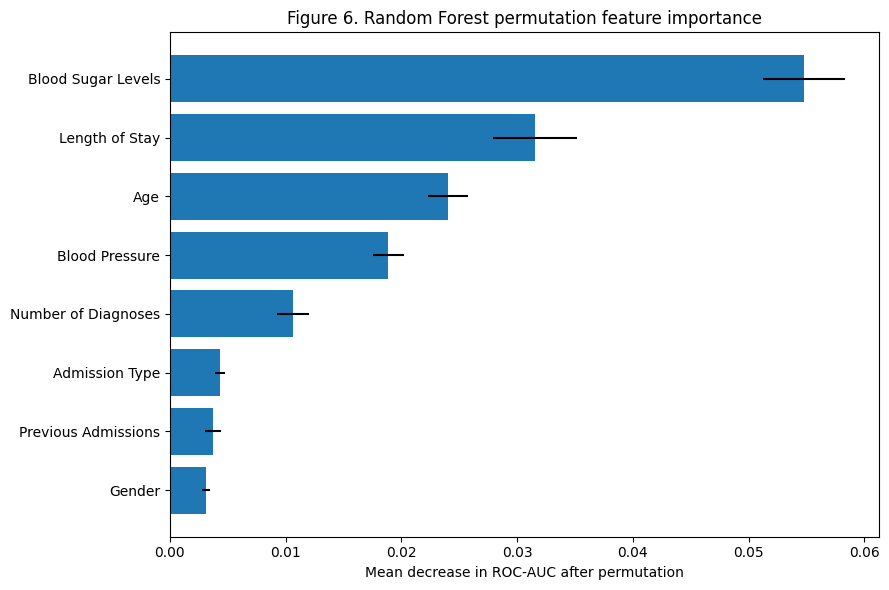

In [0]:
# Plot the permutation importance ranking.
importance_plot = permutation_summary.sort_values("Permutation importance mean")
plt.figure(figsize=(9, 6))
plt.barh(
    importance_plot["Feature"],
    importance_plot["Permutation importance mean"],
    xerr=importance_plot["Permutation importance std"]
)
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title("Figure 6. Random Forest permutation feature importance")
plt.tight_layout()
plt.show()


In [0]:
# 3.4 Combine statistical tests, mutual information and permutation importance.
feature_selection_summary = (
    statistical_results_df
    .merge(mi_summary, on="Feature", how="left")
    .merge(permutation_summary, on="Feature", how="left")
)

# Add an evidence-based initial recommendation.
# This is a prompt for human review, not an automatic final decision.
feature_selection_summary["Statistically associated (p < 0.05)"] = (
    feature_selection_summary["P-value"] < 0.05
)

display(feature_selection_summary.round(4))



Feature,Test,Statistic,P-value,Effect size,Mutual information,Permutation importance mean,Permutation importance std,Statistically associated (p < 0.05)
Gender,Chi-square,1.0156,0.3136,null,0.01,0.0032,4.0E-4,false
Admission Type,Chi-square,2.4937,0.1143,null,0.0,0.0043,5.0E-4,false
Age,Mann–Whitney U,610242.5,0.2225,0.0317,0.0087,0.024,0.0017,false
Length of Stay,Mann–Whitney U,603443.0,0.4364,0.0202,0.0,0.0315,0.0036,false
Number of Diagnoses,Mann–Whitney U,600195.0,0.5685,0.0147,0.0053,0.0106,0.0014,false
Blood Pressure,Mann–Whitney U,592800.5,0.9314,0.0022,0.0,0.0189,0.0014,false
Blood Sugar Levels,Mann–Whitney U,602612.5,0.4691,0.0188,0.0,0.0548,0.0035,false
Previous Admissions,Mann–Whitney U,588022.5,0.8188,-0.0058,0.0,0.0037,7.0E-4,false


In [0]:
# Build a decision table. Patient ID is already excluded from candidate features.
# Keep all candidate predictors provisionally until the evidence and clinical
# availability are reviewed. Document any later removal with a clear reason.
feature_decision = feature_selection_summary[[
    "Feature", "Test", "P-value", "Effect size",
    "Mutual information", "Permutation importance mean"
]].copy()

feature_decision["Decision"] = "Review; provisionally keep"
feature_decision["Justification"] = (
    "Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
)

display(feature_decision.round(4))

# For the initial model comparison, retain the candidate features.
# Change this list only when you can justify a keep/drop decision in your report.
selected_features = feature_columns.copy()
print("Features selected for modelling:", selected_features)


Feature,Test,P-value,Effect size,Mutual information,Permutation importance mean,Decision,Justification
Gender,Chi-square,0.3136,null,0.01,0.0032,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Admission Type,Chi-square,0.1143,null,0.0,0.0043,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Age,Mann–Whitney U,0.2225,0.0317,0.0087,0.024,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Length of Stay,Mann–Whitney U,0.4364,0.0202,0.0,0.0315,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Number of Diagnoses,Mann–Whitney U,0.5685,0.0147,0.0053,0.0106,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Blood Pressure,Mann–Whitney U,0.9314,0.0022,0.0,0.0189,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Blood Sugar Levels,Mann–Whitney U,0.4691,0.0188,0.0,0.0548,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."
Previous Admissions,Mann–Whitney U,0.8188,-0.0058,0.0,0.0037,Review; provisionally keep,"Consider statistical evidence, effect size, redundancy, discharge-time availability and fairness."


Features selected for modelling: ['Age', 'Gender', 'Admission Type', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions']


## Task 4 — Model building

 


In [0]:
# 4.1 Import classifiers and cross-validation tools.
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score



In [0]:
# Create a scoring dictionary that explicitly treats Yes as the positive class.
model_scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision_yes": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall_yes": make_scorer(recall_score, pos_label="Yes", zero_division=0),
    "f1_yes": make_scorer(f1_score, pos_label="Yes", zero_division=0)
}

# Use the same stratified five folds for every candidate model.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)



In [0]:
# Define the four models to compare.
candidate_models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=200,
        random_state=42, n_jobs=-1
    )
}



In [0]:
# Evaluate every model using the same training data and cross-validation folds.
cv_results = []
for model_name, classifier in candidate_models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        model_pipeline,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring=model_scoring,
        n_jobs=-1
    )

    # Record mean and standard deviation to show both performance and stability.
    cv_results.append({
        "Model": model_name,
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "ROC-AUC std": scores["test_roc_auc"].std(),
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Precision Yes mean": scores["test_precision_yes"].mean(),
        "Recall Yes mean": scores["test_recall_yes"].mean(),
        "F1 Yes mean": scores["test_f1_yes"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "ROC-AUC mean", ascending=False
)
display(cv_results_df.round(3))


Model,ROC-AUC mean,ROC-AUC std,Accuracy mean,Precision Yes mean,Recall Yes mean,F1 Yes mean
Random Forest,0.517,0.013,0.702,0.297,0.025,0.045
Decision Tree,0.514,0.017,0.595,0.308,0.323,0.315
Dummy baseline,0.5,0.0,0.711,0.0,0.0,0.0
Logistic Regression,0.494,0.026,0.502,0.286,0.482,0.359


### 4.2 Tune at least two candidate models



In [0]:
# Import GridSearchCV for hyperparameter tuning.
from sklearn.model_selection import GridSearchCV

# Create the Logistic Regression pipeline.
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ))
])

# C controls regularisation strength: smaller C means stronger regularisation.
logistic_grid = {
    "classifier__C": [0.01, 0.1, 1, 10]
}

# Search for the best Logistic Regression settings using training folds only.
logistic_search = GridSearchCV(
    logistic_pipeline,
    param_grid=logistic_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
logistic_search.fit(X_train[selected_features], y_train)

print("Best Logistic Regression parameters:", logistic_search.best_params_)
print("Best Logistic Regression CV ROC-AUC:", round(logistic_search.best_score_, 3))


Best Logistic Regression parameters: {'classifier__C': 10}
Best Logistic Regression CV ROC-AUC: 0.494


In [0]:
# Create the Random Forest pipeline.
forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# max_depth and min_samples_leaf control tree complexity.
forest_grid = {
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

# Search for the best Random Forest settings using training folds only.
forest_search = GridSearchCV(
    forest_pipeline,
    param_grid=forest_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
forest_search.fit(X_train[selected_features], y_train)

print("Best Random Forest parameters:", forest_search.best_params_)
print("Best Random Forest CV ROC-AUC:", round(forest_search.best_score_, 3))


Best Random Forest parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1}
Best Random Forest CV ROC-AUC: 0.524


In [0]:
# 4.3 Compare the tuned models using their training cross-validation scores.
tuned_comparison = pd.DataFrame({
    "Model": ["Tuned Logistic Regression", "Tuned Random Forest"],
    "Best CV ROC-AUC": [
        logistic_search.best_score_,
        forest_search.best_score_
    ]
})
display(tuned_comparison.round(3))

# Select the provisional model using training CV ROC-AUC only.
# Consider stability, recall, interpretability and hospital workflow as well.
if logistic_search.best_score_ >= forest_search.best_score_:
    final_model = logistic_search.best_estimator_
    final_model_name = "Tuned Logistic Regression"
else:
    final_model = forest_search.best_estimator_
    final_model_name = "Tuned Random Forest"

print("Provisional selected model:", final_model_name)


Model,Best CV ROC-AUC
Tuned Logistic Regression,0.494
Tuned Random Forest,0.524


Provisional selected model: Tuned Random Forest


## Task 5 — Model evaluation and testing 



In [0]:
# 5.1 Import the final evaluation metrics and plotting tools.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

# Fit the selected pipeline on all training records.
final_model.fit(X_train[selected_features], y_train)

# Predict the class label for each held-out test record.
y_test_pred = final_model.predict(X_test[selected_features])

# Extract the predicted probability for the Yes class.
yes_class_position = list(final_model.named_steps["classifier"].classes_).index("Yes")
y_test_probability = final_model.predict_proba(X_test[selected_features])[:, yes_class_position]

# Calculate the requested test-set metrics.
test_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Yes)", "Recall (Yes)", "F1 (Yes)", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, pos_label="Yes", zero_division=0),
        recall_score(y_test, y_test_pred, pos_label="Yes", zero_division=0),
        f1_score(y_test, y_test_pred, pos_label="Yes", zero_division=0),
        roc_auc_score((y_test == "Yes").astype(int), y_test_probability)
    ]
})

print("Final model:", final_model_name)
display(test_metrics.round(3))
print("\nClassification report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


Final model: Tuned Random Forest


Metric,Score
Accuracy,0.677
Precision (Yes),0.328
Recall (Yes),0.116
F1 (Yes),0.171
ROC-AUC,0.476



Classification report:
              precision    recall  f1-score   support

          No       0.72      0.90      0.80       427
         Yes       0.33      0.12      0.17       173

    accuracy                           0.68       600
   macro avg       0.52      0.51      0.49       600
weighted avg       0.60      0.68      0.62       600



Predicted No,Predicted Yes
386,41
153,20


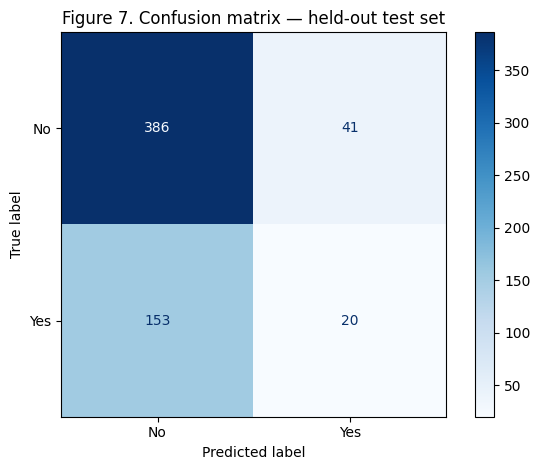

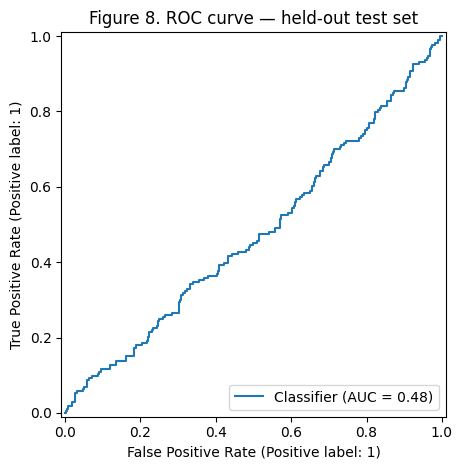

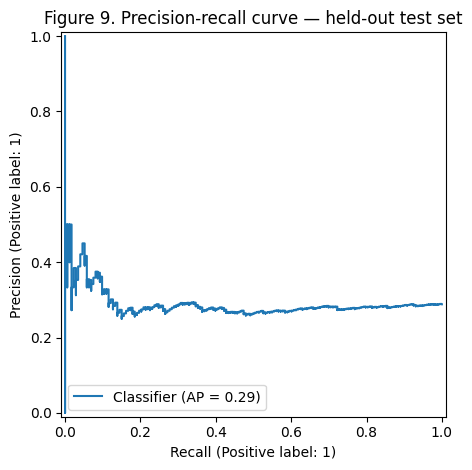

In [0]:
# 5.2 Plot the confusion matrix, ROC curve and precision-recall curve.
# Rows are actual outcomes; columns are predicted outcomes.
cm = confusion_matrix(y_test, y_test_pred, labels=["No", "Yes"])
display(pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(cmap="Blues", values_format="d")
plt.title("Figure 7. Confusion matrix — held-out test set")
plt.tight_layout()
plt.show()

# Plot the ROC curve using the probability of the Yes class.
RocCurveDisplay.from_predictions(
    (y_test == "Yes").astype(int),
    y_test_probability
)
plt.title("Figure 8. ROC curve — held-out test set")
plt.tight_layout()
plt.show()

# Plot the precision-recall curve, useful for an imbalanced target.
PrecisionRecallDisplay.from_predictions(
    (y_test == "Yes").astype(int),
    y_test_probability
)
plt.title("Figure 9. Precision-recall curve — held-out test set")
plt.tight_layout()
plt.show()


### 5.3 Explain the confusion matrix

- **True Negative (TN):** predicted No and the admission was not followed by readmission.
- **False Positive (FP):** predicted Yes but no readmission followed; this may create an unnecessary follow-up alert.
- **False Negative (FN):** predicted No but readmission followed; a patient who may need support was missed.
- **True Positive (TP):** predicted Yes and readmission followed.

Discuss the trade-off with the hospital context. Do not claim that one error is always acceptable.


### 5.4 Threshold analysis using training-only out-of-fold predictions

The default probability threshold is 0.50. To avoid using the held-out test set to choose a threshold, calculate out-of-fold probabilities on the training data. Use this table to discuss possible thresholds. The hospital should choose an operating threshold based on its capacity and the relative consequences of missed readmissions and unnecessary alerts.


Threshold,Precision (Yes),Recall (Yes),F1 (Yes)
0.2,0.293,0.994,0.452
0.3,0.301,0.869,0.447
0.4,0.302,0.465,0.366
0.5,0.304,0.11,0.161
0.6,0.25,0.004,0.009
0.7,0.0,0.0,0.0


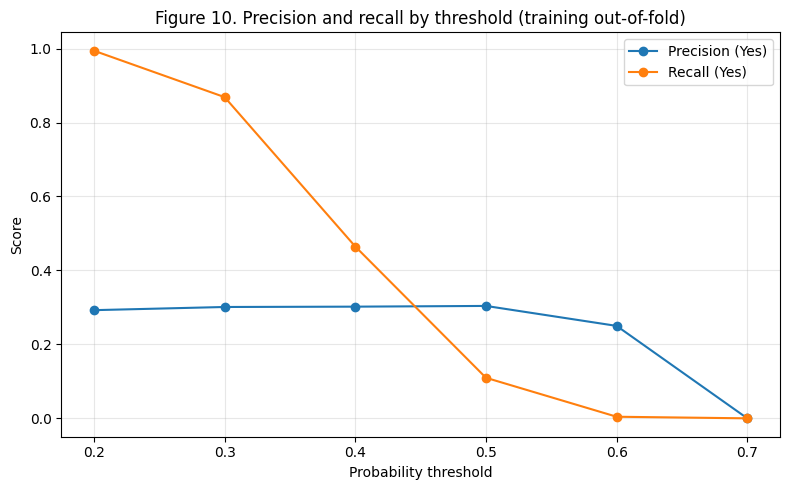

In [0]:
# Import cross_val_predict to generate out-of-fold probabilities from training data.
from sklearn.model_selection import cross_val_predict

# Generate probabilities for training records without predicting each record
# from a model that was trained on that same record.
oof_probabilities = cross_val_predict(
    final_model,
    X_train[selected_features],
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Find the probability column representing the Yes class.
oof_yes_position = list(final_model.named_steps["classifier"].classes_).index("Yes")
oof_probability_yes = oof_probabilities[:, oof_yes_position]

# Compare precision and recall at selected thresholds on out-of-fold predictions.
threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_predictions = np.where(oof_probability_yes >= threshold, "Yes", "No")

    threshold_rows.append({
        "Threshold": threshold,
        "Precision (Yes)": precision_score(
            y_train, threshold_predictions, pos_label="Yes", zero_division=0
        ),
        "Recall (Yes)": recall_score(
            y_train, threshold_predictions, pos_label="Yes", zero_division=0
        ),
        "F1 (Yes)": f1_score(
            y_train, threshold_predictions, pos_label="Yes", zero_division=0
        )
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

# Plot the precision-recall trade-off across the selected thresholds.
plt.figure(figsize=(8, 5))
plt.plot(threshold_table["Threshold"], threshold_table["Precision (Yes)"],
         marker="o", label="Precision (Yes)")
plt.plot(threshold_table["Threshold"], threshold_table["Recall (Yes)"],
         marker="o", label="Recall (Yes)")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Figure 10. Precision and recall by threshold (training out-of-fold)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.5 Check overfitting and learning behaviour

Compare training and test ROC-AUC, then use a learning curve based on cross-validation within the training set. A large gap can indicate overfitting, but interpret it alongside fold-to-fold variability and sample size.


Dataset,ROC-AUC
Training,0.999
Test,0.476


Absolute train-test ROC-AUC gap: 0.523


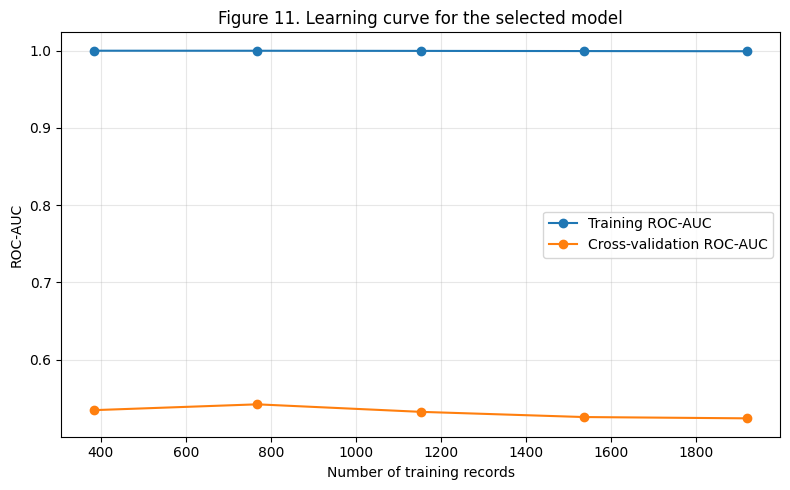

In [0]:
# Calculate the training and test ROC-AUC for the selected final model.
y_train_probability = final_model.predict_proba(X_train[selected_features])[:, yes_class_position]

train_roc_auc = roc_auc_score(
    (y_train == "Yes").astype(int),
    y_train_probability
)
test_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_test_probability
)

overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "ROC-AUC": [train_roc_auc, test_roc_auc]
})
display(overfitting_check.round(3))
print("Absolute train-test ROC-AUC gap:", round(abs(train_roc_auc - test_roc_auc), 3))

# Plot a learning curve using training data only.
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    final_model,
    X_train[selected_features],
    y_train,
    cv=cv,
    scoring="roc_auc",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

# Calculate the mean ROC-AUC at each training size.
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training ROC-AUC")
plt.plot(train_sizes, validation_mean, marker="o", label="Cross-validation ROC-AUC")
plt.xlabel("Number of training records")
plt.ylabel("ROC-AUC")
plt.title("Figure 11. Learning curve for the selected model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.6 Interpret the selected model

The feature-selection task already reports permutation importance for original input columns. The following cell adds model-specific interpretation for the final fitted model where supported. Importance is not proof of causation.


In [0]:
# Retrieve the fitted preprocessing and classifier components.
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_classifier = final_model.named_steps["classifier"]

# Retrieve the names of the transformed columns, including one-hot categories.
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# Display Random Forest impurity-based importance when available.
if hasattr(fitted_classifier, "feature_importances_"):
    model_importance = pd.DataFrame({
        "Transformed feature": transformed_feature_names,
        "Importance": fitted_classifier.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(model_importance.head(20))

# Display Logistic Regression coefficients when available.
elif hasattr(fitted_classifier, "coef_"):
    model_coefficients = pd.DataFrame({
        "Transformed feature": transformed_feature_names,
        "Coefficient": fitted_classifier.coef_[0]
    })
    model_coefficients["Absolute coefficient"] = model_coefficients["Coefficient"].abs()
    display(model_coefficients.sort_values(
        "Absolute coefficient", ascending=False
    ).head(20))
else:
    print("The selected classifier does not expose coefficients or built-in feature importance.")


Transformed feature,Importance
numeric__Blood Sugar Levels,0.2127162258966301
numeric__Blood Pressure,0.19407946561728784
numeric__Age,0.18206306602529823
numeric__Length of Stay,0.1617191405137313
numeric__Number of Diagnoses,0.10308047360576368
numeric__Previous Admissions,0.07588884495529385
categorical__Gender_Female,0.01999327660499134
categorical__Gender_Male,0.018938958518376656
categorical__Admission Type_Elective,0.016344096361730842
categorical__Admission Type_Emergency,0.015176451900896162
